# 基于颜色直方图与预训练深度特征的“以图搜图”实验

本 Notebook 对应课程作业要求，实现并验证基于内容的图像检索（CBIR）流程：
1. **数据集构建与划分**：包含 10 个语义类别，每类选取 2 张图片组成查询集（共 20 张）。
2. **图像读取与预处理**：统一进行 EXIF 方向校正与 RGB 三通道转换；深度特征分支执行与 ImageNet 预训练一致的缩放、中心裁剪与均值方差归一化。
3. **特征提取**：分别实现 16-bin RGB 三通道归一化直方图（48 维）** 与 预训练 ResNet-50 全局池化特征（2048 维），均输出 $L_2$ 归一化特征。
4. **相似度计算与排序**：采用余弦相似度（并验证其与单位球面上欧氏距离排序的等价性），返回排名前 5 的检索结果。
5. **检索结果可视化与对比分析**：展示全部 20 张查询图的 Top-5 检索结果，并结合定量指标与典型案例对比两种特征的优缺点。

## 1. 数据集构建与类别分布统计

类别总数：10 类
查询集图片总数：20 张（每类 2 张）
检索库图片总数：9469 张


,类别名称,查询集数量,检索库数量
0,English springer,2,955
1,French horn,2,956
2,cassette player,2,993
3,chain saw,2,858
4,church,2,941
5,garbage truck,2,961
6,gas pump,2,931
7,golf ball,2,951
8,parachute,2,960
9,tench,2,963


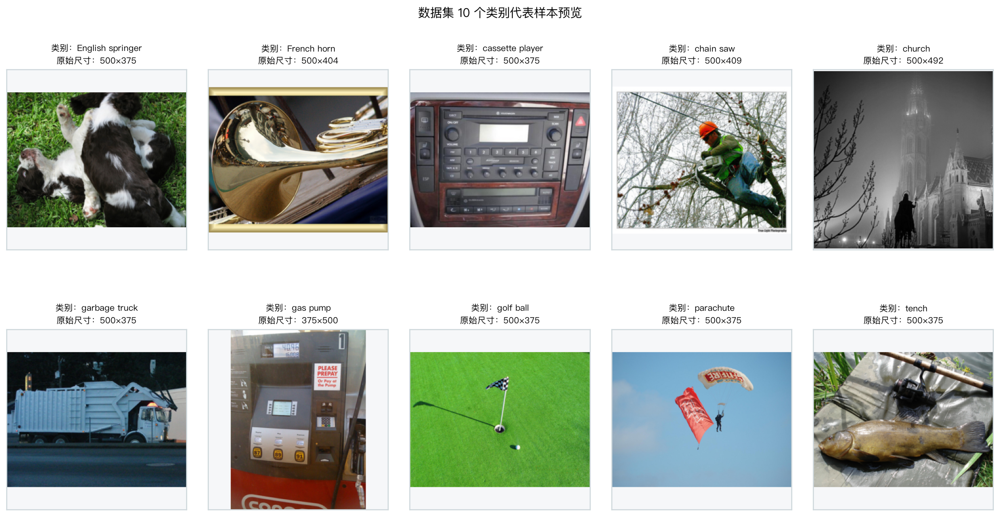

In [1]:
%load_ext autoreload
%autoreload 2

from collections import Counter
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as DisplayImage, display
from PIL import Image, ImageOps

from cbir import (
    DeepFeatureExtractor,
    FeatureGallery,
    HistogramFeatureExtractor,
    SearchResult,
    list_image_paths,
    load_rgb_image,
    plot_method_comparison,
    plot_search_results,
    select_query_paths,
)

DATASET_ROOT = Path("dataset")
GALLERY_ROOT = DATASET_ROOT / "gallery"
QUERY_ROOT = DATASET_ROOT / "query"
RESULT_ROOT = Path("results/notebook")
RESULT_ROOT.mkdir(parents=True, exist_ok=True)

# 每类固定选取 2 张作为查询集，检索库使用 gallery 中的全部图片
gallery_paths = list_image_paths(GALLERY_ROOT)
query_paths = select_query_paths(QUERY_ROOT, per_category=2)

categories = sorted({path.parent.name for path in gallery_paths})

gallery_counts = Counter(path.parent.name for path in gallery_paths)
query_counts = Counter(path.parent.name for path in query_paths)

print(f"类别总数：{len(categories)} 类")
print(f"查询集图片总数：{len(query_paths)} 张（每类 {len(query_paths) // len(categories)} 张）")
print(f"检索库图片总数：{len(gallery_paths)} 张")
dataset_df = pd.DataFrame(
    {
        "类别名称": categories,
        "查询集数量": [query_counts[cat] for cat in categories],
        "检索库数量": [gallery_counts[cat] for cat in categories],
    }
)
display(dataset_df)

# 每个类别取第 1 张查询图展示数据集样本预览
sample_paths = query_paths[::2]
fig, axes = plt.subplots(2, 5, figsize=(15.5, 8.2), squeeze=False)
for ax, path in zip(axes.flat, sample_paths):
    raw_img = load_rgb_image(path)
    w, h = raw_img.size
    canvas = ImageOps.pad(raw_img, (280, 280), method=Image.Resampling.BILINEAR, color=(246, 247, 249))
    ax.imshow(canvas)
    ax.set_title(f"类别：{path.parent.name}\n原始尺寸：{w}×{h}", fontsize=9.5, pad=7)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_color("#cfd8dc")
        spine.set_linewidth(1.2)

fig.suptitle("数据集 10 个类别代表样本预览", fontsize=13.5, y=0.98)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.subplots_adjust(hspace=0.32, wspace=0.12)
sample_fig_path = RESULT_ROOT / "dataset_samples.png"
fig.savefig(sample_fig_path, dpi=135, bbox_inches="tight")
plt.close(fig)
display(DisplayImage(filename=str(sample_fig_path)))

## 2. 图像读取、预处理与特征提取验证

- **RGB 颜色直方图**：读取并校正图像为标准 RGB 三通道格式，在 `[0, 256)` 范围内按每通道 16 个区间统计像素占比（除以总像素数消除分辨率差异），拼接为 48 维向量后再做 $L_2$ 归一化。
- **ResNet-50 深度特征**：使用 `ResNet50_Weights.IMAGENET1K_V2` 对应的标准预处理（短边缩放至 232、中心裁剪至 $224\times 224$、按 ImageNet 均值与标准差标准化），截取全局平均池化层输出的 2048 维特征并做 $L_2$ 归一化。

示例图片：dataset/query/English springer/ILSVRC2012_val_00004650.JPEG (原始尺寸: 500×375)
RGB 单通道直方图形状：(3, 16)，各通道概率和：[1. 1. 1.]
颜色特征类型：HistogramFeatureExtractor，维度：(48,)，L2 范数：1.0000
ResNet-50 预处理变换：ImageClassification(
    crop_size=[224]
    resize_size=[232]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
深度特征类型：DeepFeatureExtractor，维度：(2048,)，L2 范数：1.0000


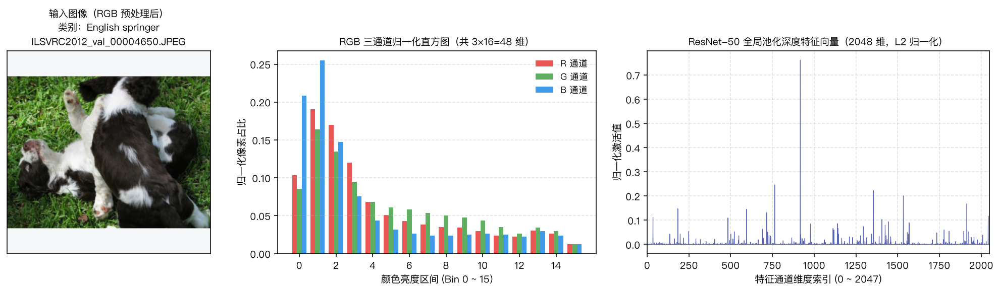

In [2]:
histogram_extractor = HistogramFeatureExtractor(bins_per_channel=16)
deep_extractor = DeepFeatureExtractor()

demo_query = query_paths[0]
raw_rgb = load_rgb_image(demo_query)
channel_hists = histogram_extractor.extract_channel_histograms(demo_query)
hist_feature = histogram_extractor.extract(demo_query)
deep_feature = deep_extractor.extract(demo_query)
hist_vec = hist_feature.vector
deep_vec = deep_feature.vector

print(f"示例图片：{demo_query} (原始尺寸: {raw_rgb.size[0]}×{raw_rgb.size[1]})")
print(f"RGB 单通道直方图形状：{channel_hists.shape}，各通道概率和：{channel_hists.sum(axis=1).round(4)}")
print(f"颜色特征类型：{hist_feature.feature_name}，维度：{hist_vec.shape}，L2 范数：{np.linalg.norm(hist_vec):.4f}")
print(f"ResNet-50 预处理变换：{deep_extractor.preprocess}")
print(f"深度特征类型：{deep_feature.feature_name}，维度：{deep_vec.shape}，L2 范数：{np.linalg.norm(deep_vec):.4f}")

# 可视化单张图片的特征提取结果
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.0), squeeze=False, gridspec_kw={"width_ratios": [1.0, 1.35, 1.45]})
ax0, ax1, ax2 = axes[0, 0], axes[0, 1], axes[0, 2]
canvas = ImageOps.pad(raw_rgb, (280, 280), method=Image.Resampling.BILINEAR, color=(246, 247, 249))
ax0.imshow(canvas)
ax0.set_title(f"输入图像（RGB 预处理后）\n类别：{demo_query.parent.name}\n{demo_query.name}", fontsize=10)
ax0.set_xticks([])
ax0.set_yticks([])

bins = histogram_extractor.bins_per_channel
x = np.arange(bins)
for idx, (color, label) in enumerate(zip(("#e53935", "#43a047", "#1e88e5"), ("R 通道", "G 通道", "B 通道"))):
    ax1.bar(x + (idx - 1) * 0.26, channel_hists[idx], width=0.26, color=color, alpha=0.85, label=label)
ax1.set_title(f"RGB 三通道归一化直方图（共 3×{bins}={len(hist_vec)} 维）", fontsize=10)
ax1.set_xlabel("颜色亮度区间 (Bin 0 ~ 15)")
ax1.set_ylabel("归一化像素占比")
ax1.set_xticks(x[::2])
ax1.grid(axis="y", linestyle="--", alpha=0.35)
ax1.legend(frameon=False, fontsize=9)

ax2.plot(np.arange(len(deep_vec)), deep_vec, color="#3949ab", linewidth=0.6, alpha=0.85)
ax2.set_title(f"ResNet-50 全局池化深度特征向量（{len(deep_vec)} 维，L2 归一化）", fontsize=10)
ax2.set_xlabel(f"特征通道维度索引 (0 ~ {len(deep_vec) - 1})")
ax2.set_ylabel("归一化激活值")
ax2.set_xlim(0, len(deep_vec))
ax2.grid(linestyle="--", alpha=0.35)

fig.tight_layout()
feat_fig_path = RESULT_ROOT / "feature_illustration.png"
fig.savefig(feat_fig_path, dpi=140, bbox_inches="tight")
plt.close(fig)
display(DisplayImage(filename=str(feat_fig_path)))

## 3. 基于 RGB 颜色直方图的以图搜图与 Top-5 可视化

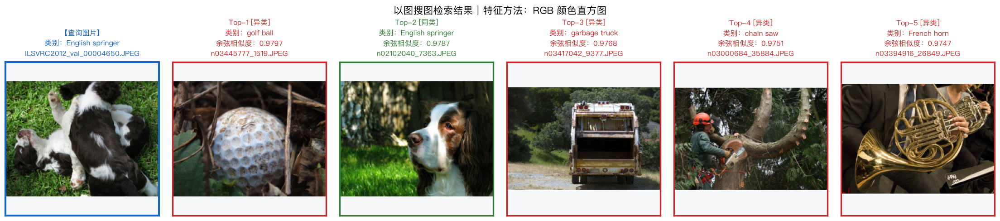

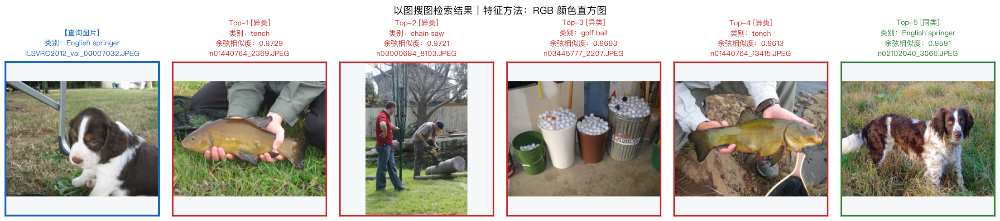

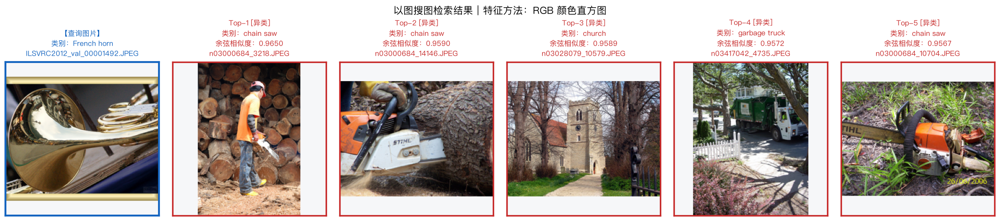

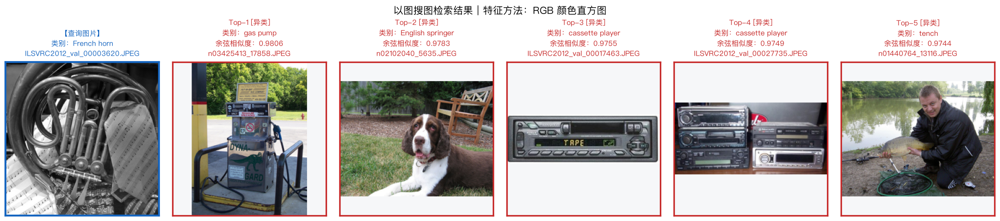

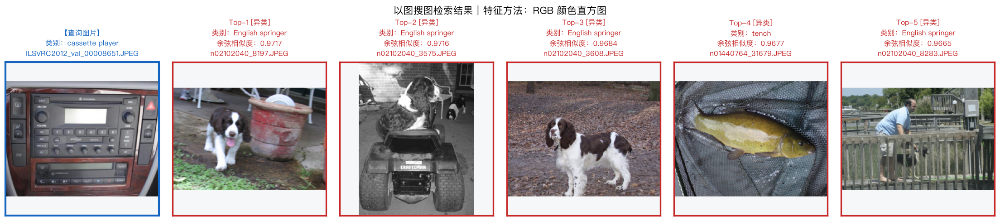

...

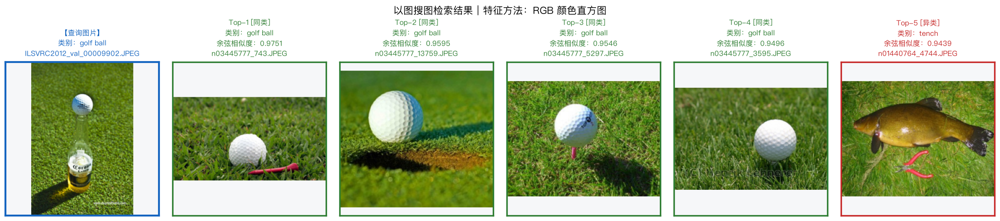

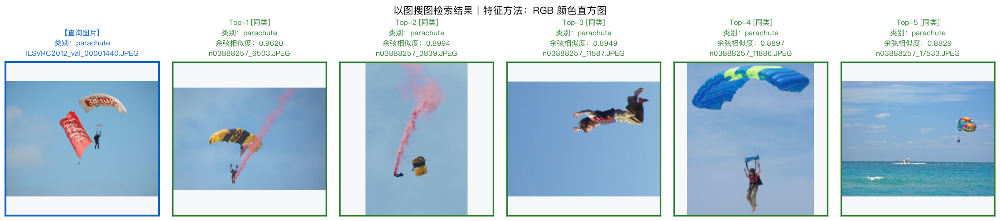

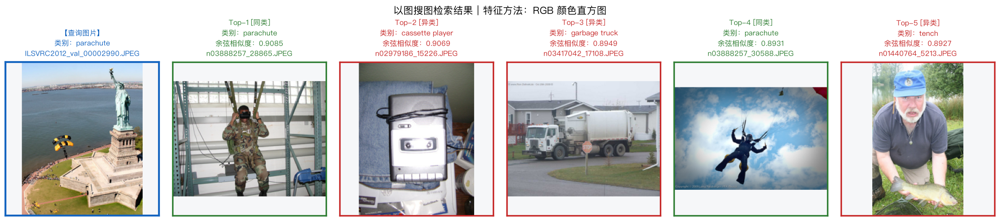

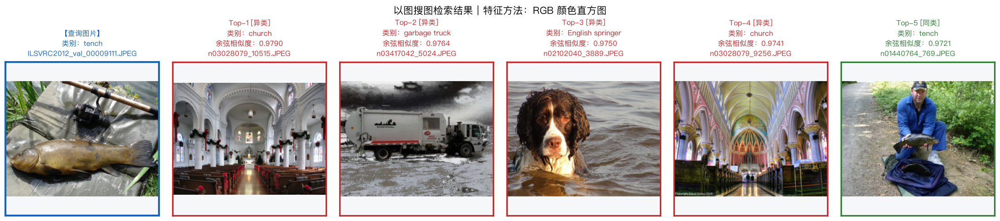

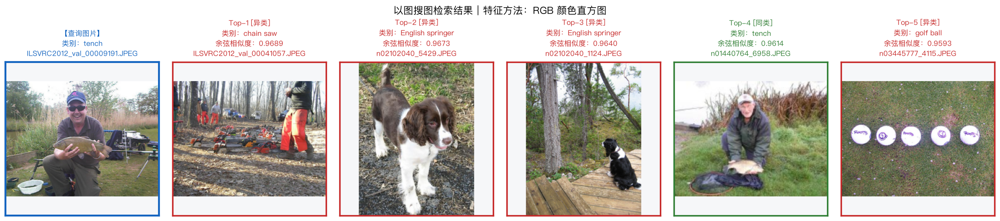

RGB 颜色直方图检索完成，共生成 20 张 Top-5 可视化结果图。


In [3]:
histogram_gallery = FeatureGallery.build_or_load(
    gallery_paths,
    histogram_extractor,
    cache_path=Path("cache/histogram_gallery.npz"),
)

histogram_runs: list[tuple[Path, list[SearchResult]]] = []
for index, query_path in enumerate(query_paths, start=1):
    query_feature = histogram_extractor.extract(query_path)
    results = histogram_gallery.search(query_feature, top_k=5, metric="cosine")
    save_path = RESULT_ROOT / "histogram" / f"{index:02d}_{query_path.parent.name}.png"
    fig = plot_search_results(
        query_path=query_path,
        results=results,
        feature_method="RGB 颜色直方图",
        save_path=save_path,
        show=False,
    )
    plt.close(fig)
    display(DisplayImage(filename=str(save_path)))
    histogram_runs.append((query_path, results))

print(f"RGB 颜色直方图检索完成，共生成 {len(histogram_runs)} 张 Top-5 可视化结果图。")

## 4. 基于预训练 ResNet-50 深度特征的以图搜图与 Top-5 可视化

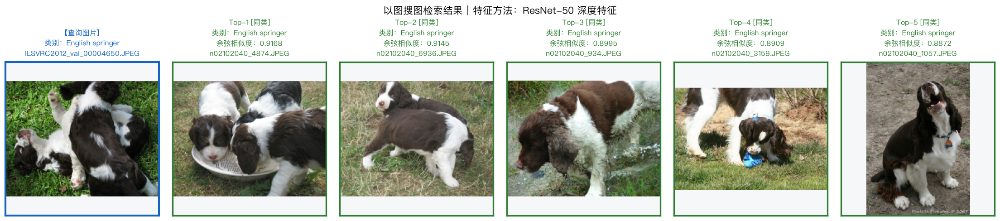

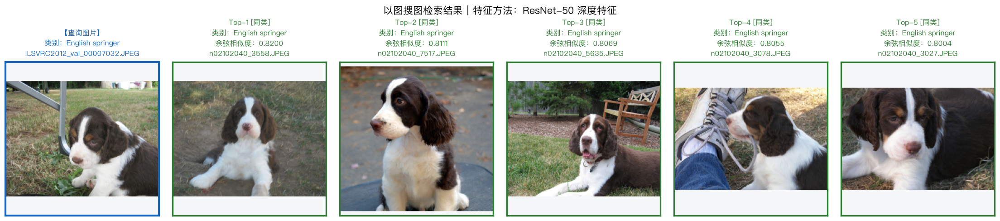

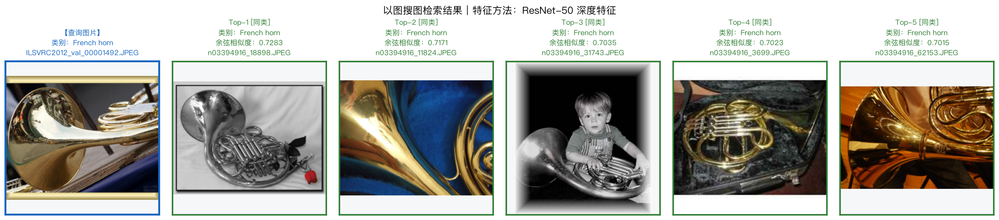

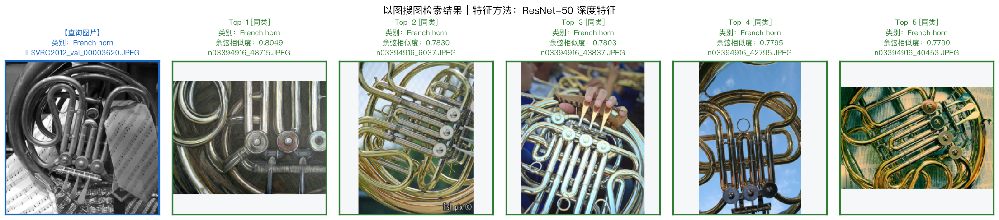

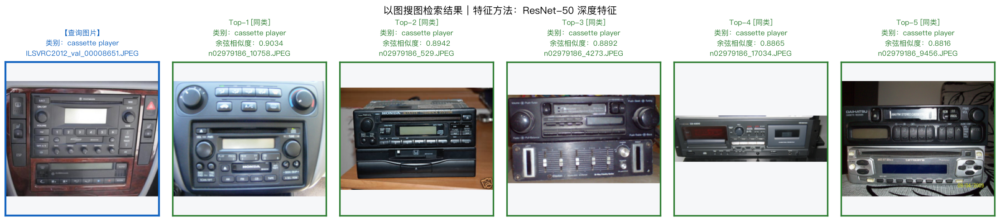

...

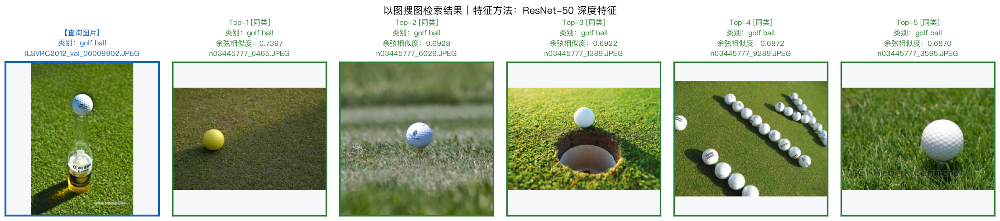

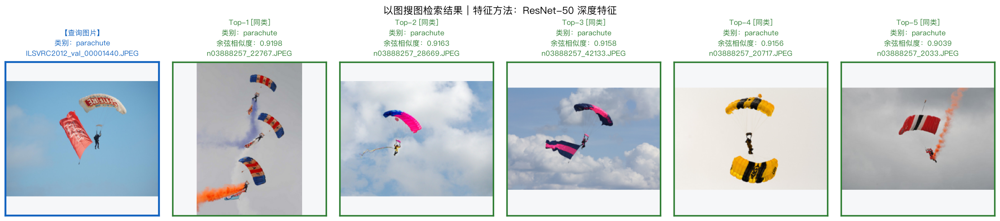

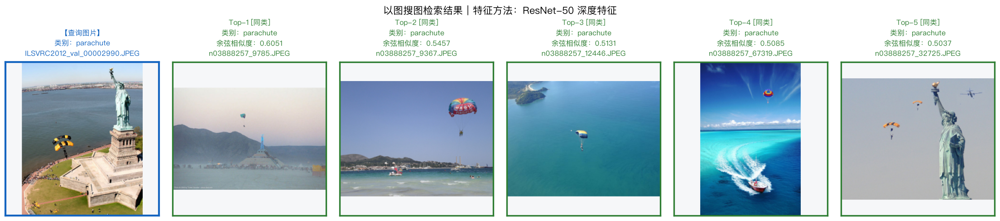

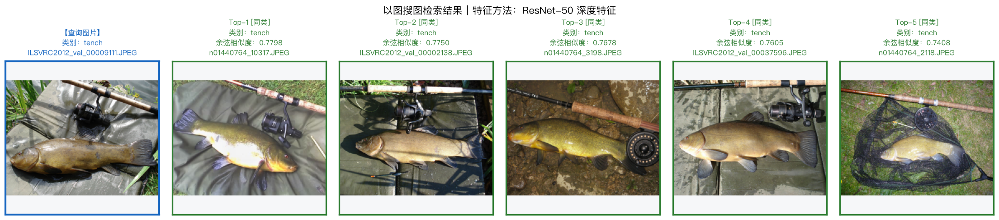

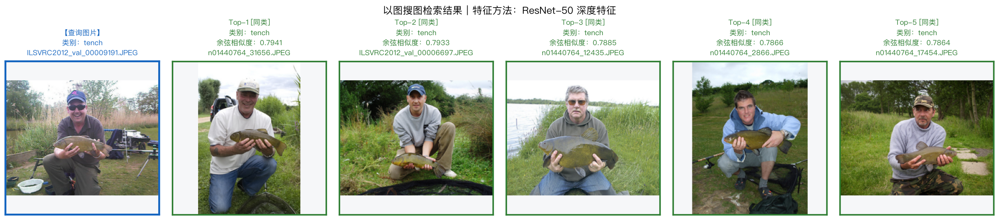

ResNet-50 深度特征检索完成，共生成 20 张 Top-5 可视化结果图。


In [4]:
deep_gallery = FeatureGallery.build_or_load(
    gallery_paths,
    deep_extractor,
    cache_path=Path("cache/deep_gallery.npz"),
)

deep_runs: list[tuple[Path, list[SearchResult]]] = []
for index, query_path in enumerate(query_paths, start=1):
    query_feature = deep_extractor.extract(query_path)
    results = deep_gallery.search(query_feature, top_k=5, metric="cosine")
    save_path = RESULT_ROOT / "deep" / f"{index:02d}_{query_path.parent.name}.png"
    fig = plot_search_results(
        query_path=query_path,
        results=results,
        feature_method="ResNet-50 深度特征",
        save_path=save_path,
        show=False,
    )
    plt.close(fig)
    display(DisplayImage(filename=str(save_path)))
    deep_runs.append((query_path, results))

print(f"ResNet-50 深度特征检索完成，共生成 {len(deep_runs)} 张 Top-5 可视化结果图。")

## 5. 定量指标统计与典型案例对比

整体检索指标对比


,特征方法,Top-1 准确率,Hit@5,Precision@5,mAP@5
0,RGB 颜色直方图,45.0%,85.0%,35.0%,49.6%
1,ResNet-50 深度特征,100.0%,100.0%,100.0%,100.0%


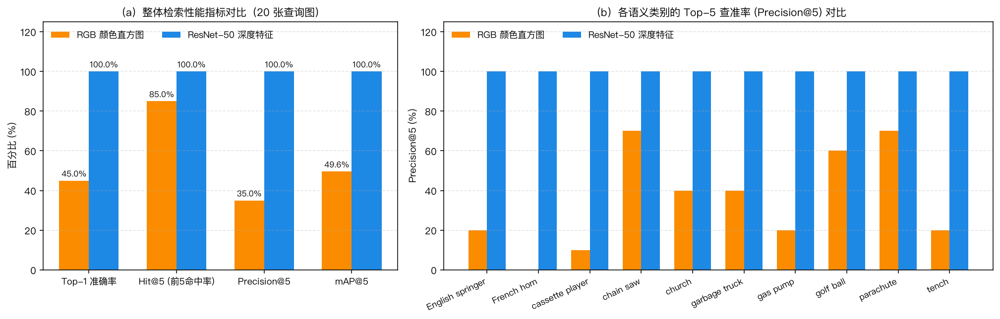

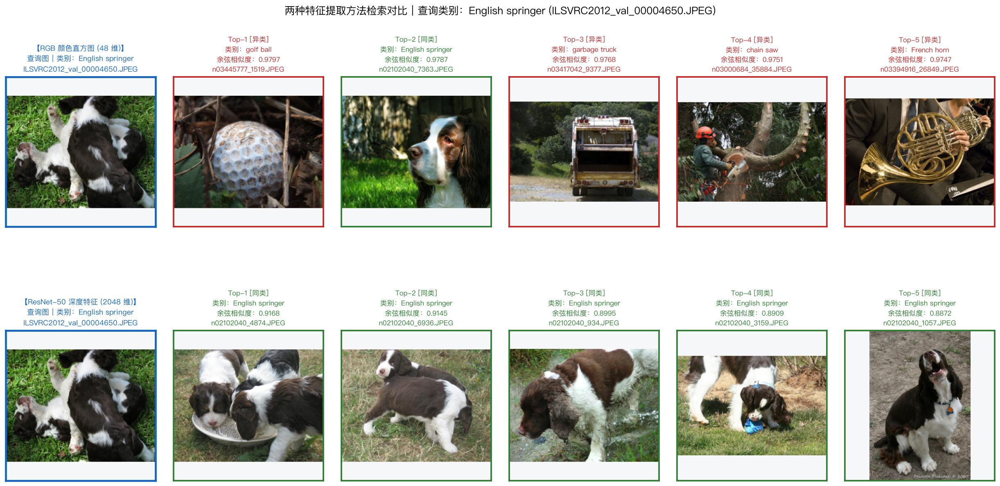

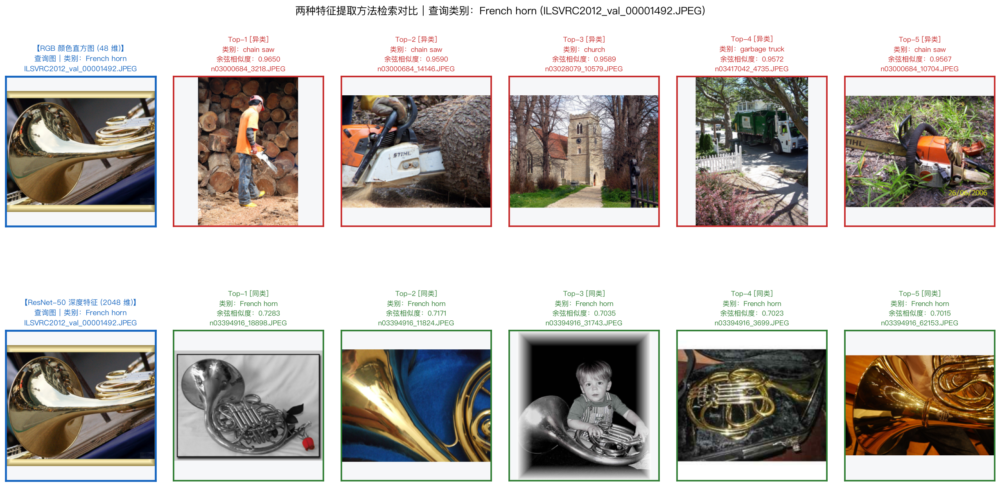

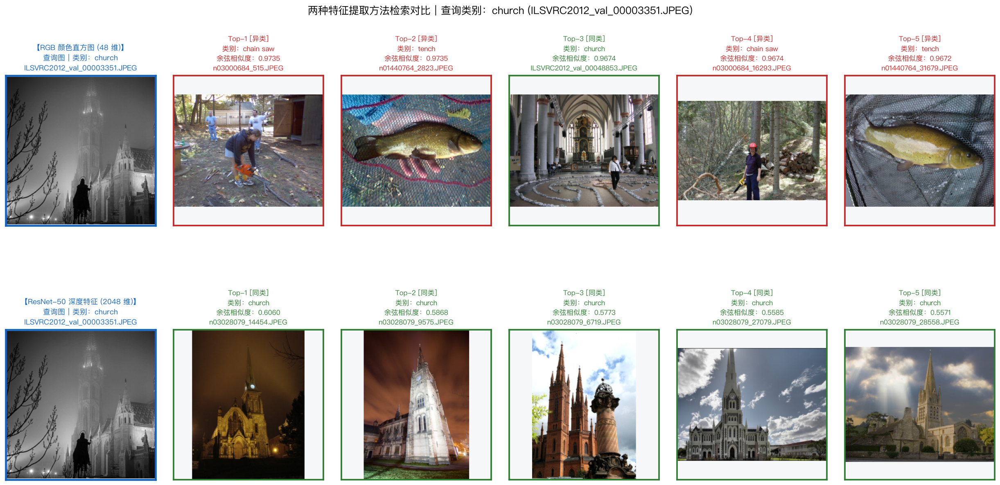

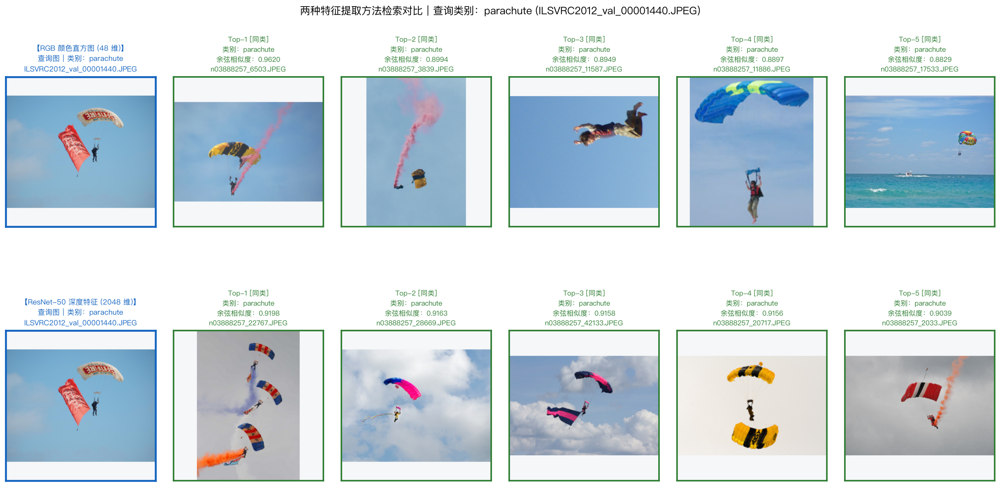

In [5]:
@dataclass
class EvalStats:
    name: str
    top1: float
    hit5: float
    p5: float
    map5: float
    cat_p5: dict[str, float]


def summarize_runs(method_name: str, runs: list[tuple[Path, list[SearchResult]]]) -> EvalStats:
    top1_hits: list[bool] = []
    hit5_flags: list[bool] = []
    p5_list: list[float] = []
    ap5_list: list[float] = []
    cat_p5: dict[str, list[float]] = {}

    for query_path, results in runs:
        q_cat = query_path.parent.name
        hits = [r.category == q_cat for r in results]
        top1_hits.append(bool(hits[0]))
        hit5_flags.append(any(hits))
        p5 = sum(hits) / len(hits)
        p5_list.append(p5)
        cat_p5.setdefault(q_cat, []).append(p5)

        running_hits, precision_sum = 0, 0.0
        for rank, is_hit in enumerate(hits, start=1):
            if is_hit:
                running_hits += 1
                precision_sum += running_hits / rank
        ap5_list.append(precision_sum / running_hits if running_hits else 0.0)

    return EvalStats(
        name=method_name,
        top1=float(np.mean(top1_hits)),
        hit5=float(np.mean(hit5_flags)),
        p5=float(np.mean(p5_list)),
        map5=float(np.mean(ap5_list)),
        cat_p5={cat: float(np.mean(vals)) for cat, vals in sorted(cat_p5.items())},
    )


hist_stats = summarize_runs("RGB 颜色直方图", histogram_runs)
deep_stats = summarize_runs("ResNet-50 深度特征", deep_runs)

print("整体检索指标对比")
metrics_df = pd.DataFrame(
    [
        {
            "特征方法": st.name,
            "Top-1 准确率": f"{st.top1:.1%}",
            "Hit@5": f"{st.hit5:.1%}",
            "Precision@5": f"{st.p5:.1%}",
            "mAP@5": f"{st.map5:.1%}",
        }
        for st in (hist_stats, deep_stats)
    ]
)
display(metrics_df)

# 绘制整体指标与分类别 Precision@5 对比柱状图
fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.7), squeeze=False, gridspec_kw={"width_ratios": [1.0, 1.55]})
ax1, ax2 = axes[0, 0], axes[0, 1]
metric_labels = ["Top-1 准确率", "Hit@5 (前5命中率)", "Precision@5", "mAP@5"]
x1 = np.arange(len(metric_labels))
hist_overall = [hist_stats.top1 * 100, hist_stats.hit5 * 100, hist_stats.p5 * 100, hist_stats.map5 * 100]
deep_overall = [deep_stats.top1 * 100, deep_stats.hit5 * 100, deep_stats.p5 * 100, deep_stats.map5 * 100]
bars_h = ax1.bar(x1 - 0.17, hist_overall, width=0.34, color="#fb8c00", label=hist_stats.name)
bars_d = ax1.bar(x1 + 0.17, deep_overall, width=0.34, color="#1e88e5", label=deep_stats.name)
for bar in list(bars_h) + list(bars_d):
    h = bar.get_height()
    ax1.annotate(f"{h:.1f}%", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8.5)
ax1.set_xticks(x1, metric_labels, fontsize=9.5)
ax1.set_ylabel("百分比 (%)")
ax1.set_ylim(0, 125)
ax1.set_title("（a）整体检索性能指标对比（20 张查询图）", fontsize=11)
ax1.grid(axis="y", linestyle="--", alpha=0.35)
ax1.legend(loc="upper left", ncol=2, frameon=False, fontsize=9.5)

cats = list(hist_stats.cat_p5.keys())
x2 = np.arange(len(cats))
ax2.bar(x2 - 0.18, [hist_stats.cat_p5[c] * 100 for c in cats], width=0.36, color="#fb8c00", label=hist_stats.name)
ax2.bar(x2 + 0.18, [deep_stats.cat_p5[c] * 100 for c in cats], width=0.36, color="#1e88e5", label=deep_stats.name)
ax2.set_xticks(x2, cats, rotation=25, ha="right", fontsize=9)
ax2.set_ylabel("Precision@5 (%)")
ax2.set_ylim(0, 125)
ax2.set_title("（b）各语义类别的 Top-5 查准率 (Precision@5) 对比", fontsize=11)
ax2.grid(axis="y", linestyle="--", alpha=0.35)
ax2.legend(loc="upper left", ncol=2, frameon=False, fontsize=9.5)

fig.tight_layout()
eval_fig_path = RESULT_ROOT / "evaluation_comparison.png"
fig.savefig(eval_fig_path, dpi=140, bbox_inches="tight")
plt.close(fig)
display(DisplayImage(filename=str(eval_fig_path)))

# 选取 4 个典型案例进行上下同图对比（01: English springer, 03: French horn, 09: church, 17: parachute）
for case_idx in (0, 2, 8, 16):
    q_path, h_res = histogram_runs[case_idx]
    _, d_res = deep_runs[case_idx]
    cmp_path = RESULT_ROOT / f"compare_{case_idx + 1:02d}_{q_path.parent.name.replace(' ', '_')}.png"
    fig = plot_method_comparison(
        query_path=q_path,
        hist_results=h_res,
        deep_results=d_res,
        save_path=cmp_path,
        show=False,
    )
    plt.close(fig)
    display(DisplayImage(filename=str(cmp_path)))

## 6. 分析与讨论要点

1. **两种特征分别描述了哪些信息？哪些信息可能被忽略？**
   - **RGB 颜色直方图**：描述整幅图像的**全局色彩统计分布**（各通道在不同亮度区间的像素占比），具备平移与旋转不变性；但它将所有像素打散统计，**完全丢失了空间位置、边缘轮廓、局部纹理以及高层语义信息**，极易受大面积背景色（如草地、天空、暗色背景）和光照色温变化主导。例如在 `parachute`（蓝天背景）中虽有 5/5 命中，但检索出的第 3 名实际上是没有降落伞伞盖的跳伞人物（仅匹配了蓝天色调）；而在 `English springer`、`French horn`、`church` 等背景复杂或灰度图像上则产生大量异类误检。
   - **ResNet-50 深度特征**：通过深层卷积神经网络提取从边缘纹理、局部部件到整体语义的**高层语义特征**，对视角变化、光照差异和背景杂波具有强鲁棒性，在 20 张查询图上实现 100% 的 Top-1 和 Precision@5；但由于网络以“类别级分类”为预训练目标且经过全局平均池化（GAP），它会**弱化精确的空间几何坐标、细粒度局部外观差异以及同类不同个体之间的身份特征**。
2. **若任务改为“找出同一件物品的不同图片”（实例级检索），需做哪些调整与评价设计？**
   - **方法调整**：① 引入目标检测或前景分割（如 YOLO / SAM）框选前景物体，剔除背景干扰；② 特征层面结合多区域池化（GeM / R-MAC）或局部关键点描述子（SuperPoint / SIFT），利用 RANSAC 单应性变换进行**空间几何一致性验证（Spatial Verification）**重排序；③ 训练目标从交叉熵分类切换为基于实例数据的**度量学习（Triplet Loss / ArcFace）**或自监督特征（如 DINOv2），并融合前景局部颜色/纹理特征以区分“同款不同色”。
   - **评价标准**：以独立物品实例 ID 标注数据集（含多视角正样本与同类别难负样本），采用兼顾召回率与排序质量的 **mAP（Mean Average Precision）**、**Recall@$K$（R@1/R@5/R@10）**、**PR 曲线**，以及开集场景下基于相似度阈值的误识率（FAR）/ 拒识率（FRR）作为核心评价指标。